flax replacement for scientific ml and works directly with jax. 
- minimal abstraction over plain JAX: just pytrees and filtered transformations.
- Diffrax, Optimistix, or Lineax ecosystem.

In [1]:
import grain
import tensorflow_datasets as tfds
ds = tfds.as_numpy(tfds.load("mnist", split="train", batch_size=-1))
x_train = ds["image"].reshape(-1, 784).astype("float32") / 255.0
y_train = ds["label"]

train_ds = (
    grain.MapDataset.range(len(x_train))
    .shuffle(seed=42)
    .map(lambda i: {"x": x_train[i], "y": y_train[i]})
    .batch(128, drop_remainder=True)
)

I0000 00:00:1790667213.841175  654809 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1790667216.105722  654809 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1790667218.019150  654809 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [2]:
import equinox as eqx
import jax, jax.numpy as jnp, optax

class MLP(eqx.Module):
    l1: eqx.nn.Linear
    l2: eqx.nn.Linear
    def __init__(self, key):
        k1, k2 = jax.random.split(key)
        self.l1 = eqx.nn.Linear(784, 128, key=k1)
        self.l2 = eqx.nn.Linear(128, 10, key=k2)
    def __call__(self, x):              # single example
        return self.l2(jax.nn.relu(self.l1(x)))

model = MLP(jax.random.PRNGKey(0))
model

MLP(
  l1=Linear(
    weight=f32[128,784],
    bias=f32[128],
    in_features=784,
    out_features=128,
    use_bias=True
  ),
  l2=Linear(
    weight=f32[10,128],
    bias=f32[10],
    in_features=128,
    out_features=10,
    use_bias=True
  )
)

In [3]:
optim = optax.adamw(1e-3)
opt_state = optim.init(eqx.filter(model, eqx.is_array))
optim

GradientTransformationExtraArgs(init=<function chain.<locals>.init_fn at 0x7ef06c71b740>, update=<function chain.<locals>.update_fn at 0x7ef06c71b880>)

In [4]:
jax.tree.map(jnp.shape, opt_state)

(ScaleByAdamState(count=(), mu=MLP(
   l1=Linear(
     weight=(128, 784),
     bias=(128,),
     in_features=784,
     out_features=128,
     use_bias=True
   ),
   l2=Linear(
     weight=(10, 128),
     bias=(10,),
     in_features=128,
     out_features=10,
     use_bias=True
   )
 ), nu=MLP(
   l1=Linear(
     weight=(128, 784),
     bias=(128,),
     in_features=784,
     out_features=128,
     use_bias=True
   ),
   l2=Linear(
     weight=(10, 128),
     bias=(10,),
     in_features=128,
     out_features=10,
     use_bias=True
   )
 )),
 EmptyState(),
 EmptyState())

JAX arrays are immutable so it creates "new" states to pass to next iteration. But may reuse memory buffers underneath

In [5]:
@eqx.filter_jit
def train_step(model, opt_state, x, y):

    def loss_fn(model):
        logits = jax.vmap(model)(x)     # batch via vmap
        return optax.softmax_cross_entropy_with_integer_labels(logits, y).mean()

    loss, grads = eqx.filter_value_and_grad(loss_fn)(model)

    updates, opt_state = optim.update(grads, opt_state, eqx.filter(model, eqx.is_array))

    model = eqx.apply_updates(model, updates)
	
    return model, opt_state, loss

In [6]:
lossi = []
for epoch in range(10):
	for batch in train_ds:
		model, opt_state, loss = train_step(model, opt_state, batch["x"], batch["y"])
		lossi.append(loss)
	print(epoch, loss)

0 0.18746412
1 0.13669053
2 0.10460755
3 0.06633963
4 0.041212767
5 0.02623563
6 0.020255754
7 0.017535927
8 0.015267907
9 0.014642905


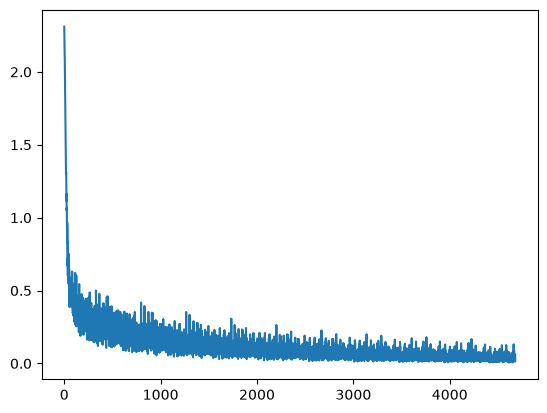

In [7]:
import matplotlib.pyplot as plt
plt.plot(lossi)